# Experiment 8 — Support Vector Machines and the Kernel Trick

In [1]:
# Imports, reproducibility, and environment information
import sys
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support,
)

# Rich display in Jupyter, with a plain-Python fallback for portability.
try:
    from IPython.display import display, Markdown
except ModuleNotFoundError:
    class Markdown:
        def __init__(self, data):
            self.data = data

        def __repr__(self):
            return self.data

        def _repr_markdown_(self):
            return self.data

    def display(*objects):
        for obj in objects:
            print(obj.to_string() if isinstance(obj, pd.DataFrame) else obj)

RANDOM_STATE = 42
N_SAMPLES = 500
NOISE = 0.25
HOLDOUT_FRACTION = 0.30

print('Python:', sys.version.split()[0])
environment = pd.DataFrame({
    'Package': ['numpy', 'pandas', 'scikit-learn', 'matplotlib'],
    'Version': [version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']],
})
print(environment.to_string(index=False))

Python: 3.13.7
     Package Version
       numpy   2.2.6
      pandas   2.3.3
scikit-learn   1.7.2
  matplotlib  3.10.7


## Background: what an SVM learns

For a linear binary classifier, the decision function is

$$f(x)=w^T x+b.$$

The decision boundary is $f(x)=0$. The SVM balances a wide margin against training errors. With labels interpreted as −1 and +1, the soft-margin objective is

$$\min_{w,b,\xi}\;\frac{1}{2}\lVert w\rVert^2+C\sum_i\xi_i,\qquad y_i(w^T x_i+b)\geq 1-\xi_i,\quad \xi_i\geq 0.$$

- **Support vectors:** training observations with nonzero dual coefficients. They determine the fitted decision function; some may lie inside the margin or even be misclassified.
- **C:** penalty on margin violations. A smaller C means stronger regularization and more tolerance for violations; a larger C penalizes violations more strongly and may fit noise.
- **Linear margin:** the distance between the reference hyperplanes $f(x)=-1$ and $f(x)=+1$ is $2/\lVert w\rVert$.

### The kernel trick

A kernel computes inner products in an implicit feature space without explicitly constructing every transformed feature:

$$f(x)=\sum_{i\in SV}\alpha_i y_i K(x_i,x)+b.$$

| Kernel | Formula | Main controls |
|---|---|---|
| Linear | $K(x,z)=x^Tz$ | C |
| Polynomial | $K(x,z)=(\gamma x^Tz+\mathrm{coef0})^d$ | C, gamma, degree, coef0 |
| RBF | $K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$ | C, gamma |

**RBF gamma** controls locality: large gamma means narrow influence around each observation; small gamma means broad influence and typically smoother boundaries. In `SVC`, `gamma='scale'` is computed as `1 / (number_of_features * X.var())` on the fitted input. With two training-standardized features it is approximately 0.5.

A kernel makes the classifier linear in its **implicit feature space**, not necessarily in the original two-dimensional coordinates. Curves at $f(x)=\pm1$ for a nonlinear SVM are decision-function reference contours, not constant Euclidean-distance margins in the original input space.

## Task 1 — Data loading and preprocessing (10 marks)

### 1.1 Generate and inspect the data

Use the handout's exact call: `make_moons(n_samples=500, noise=0.25, random_state=42)`. Each row has two continuous features, and the target is class 0 or class 1. These class labels are nominal: neither represents a larger numerical quantity. Noise introduces overlap, so even a flexible classifier need not reach 100% hold-out accuracy.

In [2]:
# Exact data-generation settings from the handout
X, y = make_moons(n_samples=N_SAMPLES, noise=NOISE, random_state=RANDOM_STATE)

assert X.shape == (500, 2)
assert y.shape == (500,)
assert np.isfinite(X).all()
assert set(np.unique(y)) == {0, 1}

data = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
data['Class'] = y
print('Feature matrix:', X.shape, '| Target vector:', y.shape)
print('Missing feature values:', int(data[['Feature 1', 'Feature 2']].isna().sum().sum()))
print('Class counts:', dict(zip(*np.unique(y, return_counts=True))))
display(data.head(8))
display(data[['Feature 1', 'Feature 2']].describe().round(4))

Feature matrix: (500, 2) | Target vector: (500,)
Missing feature values: 0
Class counts: {np.int64(0): np.int64(250), np.int64(1): np.int64(250)}


,Feature 1,Feature 2,Class
0,0.830948,-0.296546,1
1,1.088387,0.899693,0
2,1.135634,-0.462935,1
3,-0.082277,1.059718,0
4,0.443047,1.418977,0
5,1.300300,-0.537628,1
6,1.143109,-0.215442,1
7,0.131665,1.265140,0


,Feature 1,Feature 2
count,500.0000,500.0000
mean,0.5227,0.2567
std,0.9101,0.5677
min,-1.6085,-1.1174
25%,-0.0964,-0.1938
50%,0.4750,0.2813
75%,1.1605,0.7067
max,2.6419,1.6351


### 1.2 Single 70/30 split and training-only scaling

The split below reproduces the handout literally: `test_size=0.30`, `random_state=42`, and the default shuffled, **unstratified** split. A stratified split can be useful in practice, but would produce different rows and different numerical answers.

`StandardScaler` learns each feature's mean and standard deviation from **X_train only**. The same fitted scaler transforms the validation rows. SVMs depend on dot products and distances, so scaling prevents an arbitrary feature unit from dominating the margin or kernel. No imputation or categorical encoding is needed for this complete, numerical dataset.

In [3]:
# Do not fit preprocessing on the validation set.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=HOLDOUT_FRACTION, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

assert X_train.shape == (350, 2) and X_val.shape == (150, 2)
assert np.allclose(scaler.mean_, X_train.mean(axis=0))
assert np.allclose(X_train_scaled.mean(axis=0), 0.0, atol=1e-12)
assert np.allclose(X_train_scaled.std(axis=0), 1.0, atol=1e-12)
train_rows = {tuple(row) for row in X_train}
validation_rows = {tuple(row) for row in X_val}
assert train_rows.isdisjoint(validation_rows)

split_summary = pd.DataFrame([
    {'Split': name, 'Rows': len(labels), 'Share': len(labels) / len(y),
     'Class 0': int((labels == 0).sum()), 'Class 1': int((labels == 1).sum())}
    for name, labels in [('All data', y), ('Training', y_train), ('Validation', y_val)]
])
display(split_summary)

scaling_summary = pd.DataFrame({
    'Feature': ['Feature 1', 'Feature 2'],
    'Fitted training mean': scaler.mean_,
    'Fitted training std': scaler.scale_,
    'Scaled training mean': X_train_scaled.mean(axis=0),
    'Scaled training std': X_train_scaled.std(axis=0),
    'Scaled validation mean': X_val_scaled.mean(axis=0),
    'Scaled validation std': X_val_scaled.std(axis=0),
})
display(scaling_summary.round(5))
print('Validation means/stds need not be 0/1: validation statistics were not fitted.')

,Split,Rows,Share,Class 0,Class 1
0,All data,500,1.0,250,250
1,Training,350,0.7,175,175
2,Validation,150,0.3,75,75


,Feature,Fitted training mean,Fitted training std,Scaled training mean,Scaled training std,Scaled validation mean,Scaled validation std
0,Feature 1,0.50308,0.9087,0.0,1.0,0.07191,0.99982
1,Feature 2,0.23973,0.5820,0.0,1.0,0.09725,0.90824


Validation means/stds need not be 0/1: validation statistics were not fitted.


### 1.3 Reusable plotting and evaluation helpers

Figures use a fixed class-color mapping, circle/triangle markers, neutral text, shared axes for model comparisons, and lightly shaded prediction regions. Class identity remains visible without color. Tables beside the plots provide the numerical values. The light and dark categorical palettes were checked for color-vision separation and contrast.

Every decision-boundary plot evaluates the fitted model on a mesh in **standardized training coordinates**. The final required three panels use exactly the same mesh and axis limits, so differences are due to models rather than plot scaling. Outline rings identify support vectors when shown.

In [4]:
# Plotting setup: change to 'dark' and rerun all cells for dark figures.
CHART_THEME = 'light'
assert CHART_THEME in {'light', 'dark'}

THEMES = {
    'light': {
        'surface': '#fcfcfb', 'ink': '#0b0b0b', 'secondary': '#52514e',
        'grid': '#e1e0d9', 'axis': '#c3c2b7',
        'class0': '#2a78d6', 'class1': '#eb6834',
        'sequential': ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'],
    },
    'dark': {
        'surface': '#1a1a19', 'ink': '#f0efec', 'secondary': '#c3c2b7',
        'grid': '#2c2c2a', 'axis': '#383835',
        'class0': '#3987e5', 'class1': '#d95926',
        'sequential': ['#1a1a19', '#104281', '#184f95', '#256abf', '#3987e5', '#86b6ef', '#cde2fb'],
    },
}
STYLE = THEMES[CHART_THEME]
CLASS_COLORS = {0: STYLE['class0'], 1: STYLE['class1']}
CLASS_MARKERS = {0: 'o', 1: '^'}
REGION_CMAP = ListedColormap([CLASS_COLORS[0], CLASS_COLORS[1]])
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list('svm_blue_magnitude', STYLE['sequential'])

plt.rcParams.update({
    'figure.facecolor': STYLE['surface'], 'axes.facecolor': STYLE['surface'],
    'savefig.facecolor': STYLE['surface'], 'axes.edgecolor': STYLE['axis'],
    'text.color': STYLE['ink'], 'axes.labelcolor': STYLE['secondary'],
    'axes.titlecolor': STYLE['ink'], 'xtick.color': STYLE['secondary'],
    'ytick.color': STYLE['secondary'], 'grid.color': STYLE['grid'],
    'grid.linewidth': 0.6, 'grid.linestyle': '-', 'axes.grid': True,
    'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 11,
    'figure.dpi': 120, 'legend.frameon': False,
})

def scatter_classes(ax, features, labels):
    for label in (0, 1):
        subset = labels == label
        ax.scatter(features[subset, 0], features[subset, 1],
                   c=CLASS_COLORS[label], marker=CLASS_MARKERS[label], s=38,
                   edgecolors=STYLE['surface'], linewidths=1.1,
                   label=f'Class {label}', zorder=3)

def class_legend():
    return [Line2D([], [], linestyle='none', marker=CLASS_MARKERS[label],
                   markerfacecolor=CLASS_COLORS[label], markeredgecolor=STYLE['surface'],
                   markersize=8, label=f'Class {label}') for label in (0, 1)]

def boundary_legend(show_support=True, show_margins=False):
    handles = class_legend()
    handles.append(Line2D([], [], color=STYLE['ink'], lw=1.4, label='Decision boundary: f = 0'))
    if show_support:
        handles.append(Line2D([], [], linestyle='none', marker='o',
                              markerfacecolor='none', markeredgecolor=STYLE['ink'],
                              markersize=10, label='Support vector (outline)'))
    if show_margins:
        handles.append(Line2D([], [], color=STYLE['secondary'], lw=1.0,
                              linestyle='--', label='Reference margins: f = ±1'))
    return handles

def make_mesh(features, resolution=280, padding=0.6):
    x_limits = (features[:, 0].min() - padding, features[:, 0].max() + padding)
    y_limits = (features[:, 1].min() - padding, features[:, 1].max() + padding)
    xx, yy = np.meshgrid(np.linspace(*x_limits, resolution),
                         np.linspace(*y_limits, resolution))
    return xx, yy, np.column_stack([xx.ravel(), yy.ravel()])

mesh_xx, mesh_yy, mesh_points = make_mesh(X_train_scaled)

def plot_decision_regions(ax, model, title, show_support=True, show_margins=False):
    # Both predictions and decision scores use the same standardized 2D mesh.
    regions = model.predict(mesh_points).reshape(mesh_xx.shape)
    scores = model.decision_function(mesh_points).reshape(mesh_xx.shape)
    ax.contourf(mesh_xx, mesh_yy, regions, levels=[-0.5, 0.5, 1.5],
                cmap=REGION_CMAP, alpha=0.12, zorder=0)
    if scores.min() < 0 < scores.max():
        ax.contour(mesh_xx, mesh_yy, scores, levels=[0],
                   colors=[STYLE['ink']], linewidths=1.4, zorder=2)
    if show_margins:
        levels = [level for level in [-1, 1] if scores.min() < level < scores.max()]
        if levels:
            contours = ax.contour(mesh_xx, mesh_yy, scores, levels=levels,
                                  colors=[STYLE['secondary']], linestyles='--', linewidths=1.0)
            ax.clabel(contours, fmt={-1: 'f = -1', 1: 'f = +1'}, fontsize=8)
    scatter_classes(ax, X_train_scaled, y_train)
    estimator = model.best_estimator_ if hasattr(model, 'best_estimator_') else model
    if show_support:
        support = estimator.support_vectors_
        ax.scatter(support[:, 0], support[:, 1], s=100, facecolors='none',
                   edgecolors=STYLE['ink'], linewidths=0.7, zorder=4)
    ax.set(xlim=(mesh_xx.min(), mesh_xx.max()), ylim=(mesh_yy.min(), mesh_yy.max()),
           xlabel='Feature 1 (standardized)', title=title)
    ax.set_aspect('equal', adjustable='box')

def readable_cell_ink(rgba):
    # Choose white/black using contrast against the actual heatmap-cell color.
    rgb = np.asarray(rgba[:3], dtype=float)
    linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    luminance = float(linear @ np.array([0.2126, 0.7152, 0.0722]))
    contrast_white = 1.05 / (luminance + 0.05)
    contrast_black = (luminance + 0.05) / 0.05
    return '#ffffff' if contrast_white >= contrast_black else '#0b0b0b'

def evaluate_model(model, name):
    # Macro metrics give the two classes equal weight; support refers to vectors.
    train_predictions = model.predict(X_train_scaled)
    validation_predictions = model.predict(X_val_scaled)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, validation_predictions, average='macro', zero_division=0
    )
    estimator = model.best_estimator_ if hasattr(model, 'best_estimator_') else model
    result = {
        'Model': name,
        'Training accuracy': accuracy_score(y_train, train_predictions),
        'Validation accuracy': accuracy_score(y_val, validation_predictions),
        'Precision (macro)': precision, 'Recall (macro)': recall, 'F1 (macro)': f1,
        'Support vectors': int(estimator.n_support_.sum()),
    }
    print('\n' + name)
    print('-' * len(name))
    print(f"Training accuracy: {result['Training accuracy']:.4f}")
    print(f"Validation accuracy: {result['Validation accuracy']:.4f}")
    print('Support vectors by class:', estimator.n_support_.tolist())
    print(classification_report(y_val, validation_predictions,
                                labels=[0, 1], target_names=['Class 0', 'Class 1'],
                                digits=4, zero_division=0))
    return result

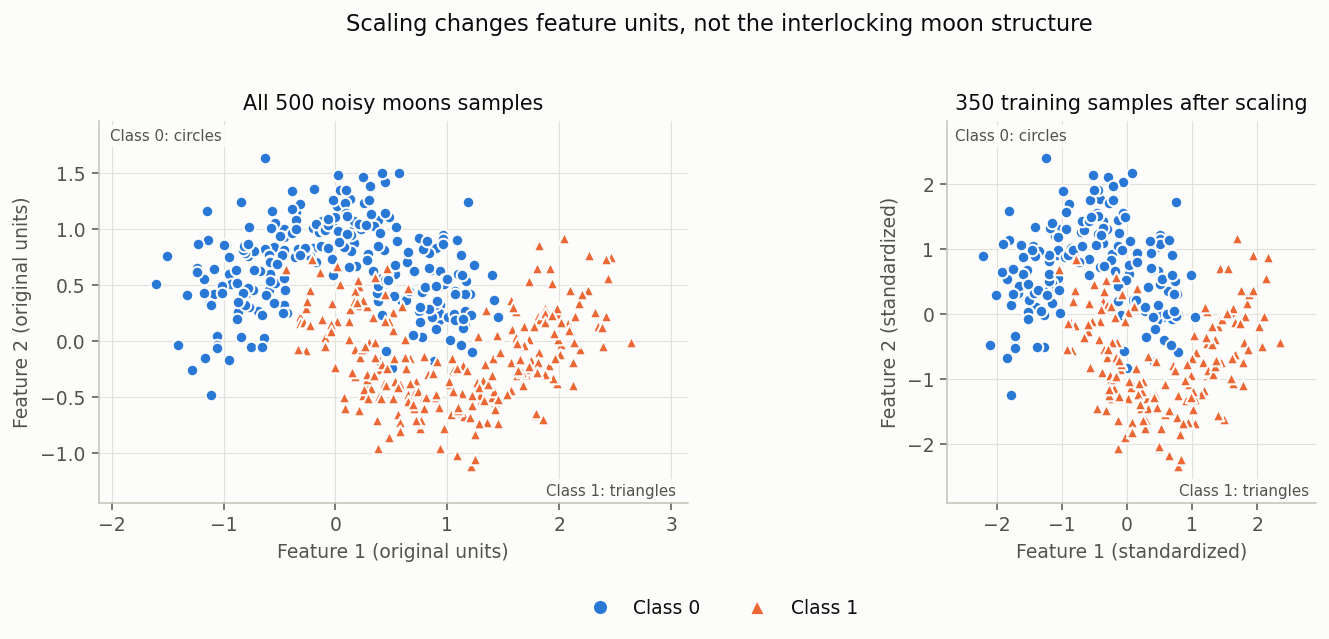

In [5]:
# Figure 1: the nonlinear geometry and the standardized training coordinates
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.7))
for ax, features, labels, title, suffix in [
    (axes[0], X, y, 'All 500 noisy moons samples', 'original units'),
    (axes[1], X_train_scaled, y_train, '350 training samples after scaling', 'standardized'),
]:
    scatter_classes(ax, features, labels)
    ax.set(title=title, xlabel=f'Feature 1 ({suffix})', ylabel=f'Feature 2 ({suffix})')
    ax.margins(0.12)
    ax.set_aspect('equal', adjustable='box')
    ax.text(0.02, 0.98, 'Class 0: circles', transform=ax.transAxes, va='top',
            color=STYLE['secondary'], fontsize=8,
            bbox={'facecolor': STYLE['surface'], 'edgecolor': 'none', 'alpha': 0.9, 'pad': 2})
    ax.text(0.98, 0.02, 'Class 1: triangles', transform=ax.transAxes, ha='right',
            color=STYLE['secondary'], fontsize=8,
            bbox={'facecolor': STYLE['surface'], 'edgecolor': 'none', 'alpha': 0.9, 'pad': 2})
fig.suptitle('Scaling changes feature units, not the interlocking moon structure', fontsize=12)
fig.legend(handles=class_legend(), loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()

## Task 2 — Model 1: linear SVM (15 marks)

Fit exactly `SVC(kernel='linear', C=1.0, random_state=42)` on the standardized training set, and evaluate it on `X_val_scaled`. A linear decision boundary can only be a straight line in this two-dimensional input space.

In [6]:
# Model 1: linear kernel with the requested C
linear_model = SVC(kernel='linear', C=1.0, random_state=RANDOM_STATE)
linear_model.fit(X_train_scaled, y_train)
linear_result = evaluate_model(linear_model, 'Linear (C=1)')

w = linear_model.coef_[0]
b = float(linear_model.intercept_[0])
linear_margin_width = 2.0 / np.linalg.norm(w)
print('w =', np.round(w, 4), '| b =', round(b, 4))
print(f'Distance between f = -1 and f = +1: {linear_margin_width:.4f} standardized units')


Linear (C=1)
------------
Training accuracy: 0.8457
Validation accuracy: 0.8533
Support vectors by class: [59, 58]
              precision    recall  f1-score   support

     Class 0     0.8442    0.8667    0.8553        75
     Class 1     0.8630    0.8400    0.8514        75

    accuracy                         0.8533       150
   macro avg     0.8536    0.8533    0.8533       150
weighted avg     0.8536    0.8533    0.8533       150

w = [ 0.7045 -1.3268] | b = -0.0328
Distance between f = -1 and f = +1: 1.3314 standardized units


### Why the linear model is not perfect

The two classes form curved, interlocking arcs, not two half-planes that one straight line can fully separate. In addition, noise creates ambiguous observations. The linear SVM can still perform substantially better than chance; the handout's description of it as 'failing' means **failing to capture the nonlinear geometry**, not being completely useless.

**What does C represent?** It multiplies the penalty for margin violations in the soft-margin objective. At `C=0.01`, violations are much cheaper than at `C=1`, so regularization is stronger. For a linear SVM this tends toward a wider margin and more tolerated training errors, while the boundary remains straight. For an RBF SVM, very small C can produce an overly simple or nearly constant classifier. The exact boundary also depends on gamma and the data; neither a large C nor a small C guarantees a particular validation score.

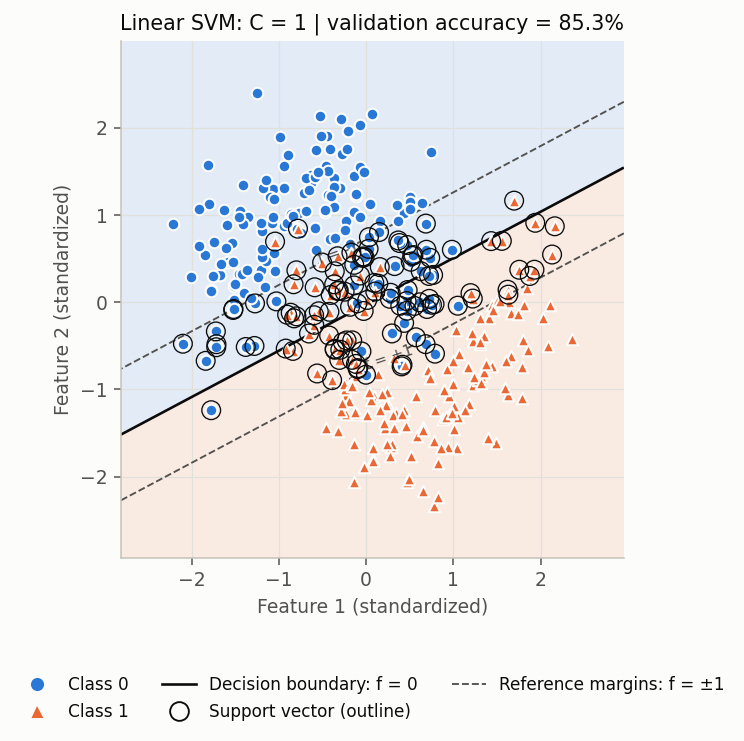

In [7]:
# Figure 2: linear decision boundary, reference margins, and support vectors
fig, ax = plt.subplots(figsize=(8.4, 5.5))
plot_decision_regions(
    ax, linear_model,
    f"Linear SVM: C = 1 | validation accuracy = {linear_result['Validation accuracy']:.1%}",
    show_support=True, show_margins=True,
)
ax.set_ylabel('Feature 2 (standardized)')
fig.legend(handles=boundary_legend(show_support=True, show_margins=True),
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, 0.0), fontsize=9)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

## Task 3 — Models 2 and 3: the kernel trick (25 marks)

### RBF and polynomial models

The default RBF model uses `C=1.0` and `gamma='scale'`. The polynomial model uses `degree=3`, `C=1.0`, `gamma='scale'` and `coef0=0.0`. We leave these defaults unchanged, as requested. A polynomial kernel is nonlinear, but degree alone does not guarantee a suitable boundary: C, gamma and coef0 also matter.

In [8]:
# Model 2: default RBF kernel
rbf_model = SVC(kernel='rbf', random_state=RANDOM_STATE)
rbf_model.fit(X_train_scaled, y_train)
rbf_result = evaluate_model(rbf_model, 'RBF (default)')

effective_scale_gamma = 1.0 / (X_train_scaled.shape[1] * X_train_scaled.var())
print(f'Effective gamma for gamma=scale: {effective_scale_gamma:.4f}')


RBF (default)
-------------
Training accuracy: 0.9457
Validation accuracy: 0.9467
Support vectors by class: [48, 47]
              precision    recall  f1-score   support

     Class 0     0.9136    0.9867    0.9487        75
     Class 1     0.9855    0.9067    0.9444        75

    accuracy                         0.9467       150
   macro avg     0.9495    0.9467    0.9466       150
weighted avg     0.9495    0.9467    0.9466       150

Effective gamma for gamma=scale: 0.5000


In [9]:
# Model 3: polynomial kernel, degree 3, otherwise defaults
poly_model = SVC(kernel='poly', degree=3, random_state=RANDOM_STATE)
poly_model.fit(X_train_scaled, y_train)
poly_result = evaluate_model(poly_model, 'Polynomial (degree=3)')
print('Polynomial settings:', {key: poly_model.get_params()[key]
                               for key in ['kernel', 'C', 'degree', 'gamma', 'coef0']})


Polynomial (degree=3)
---------------------
Training accuracy: 0.8543
Validation accuracy: 0.8733
Support vectors by class: [59, 59]
              precision    recall  f1-score   support

     Class 0     0.8333    0.9333    0.8805        75
     Class 1     0.9242    0.8133    0.8652        75

    accuracy                         0.8733       150
   macro avg     0.8788    0.8733    0.8729       150
weighted avg     0.8788    0.8733    0.8729       150

Polynomial settings: {'kernel': 'poly', 'C': 1.0, 'degree': 3, 'gamma': 'scale', 'coef0': 0.0}


In [10]:
# Required three-model validation comparison
comparison_baseline = pd.DataFrame([linear_result, rbf_result, poly_result])
print('DEFAULT-KERNEL COMPARISON')
print(comparison_baseline[['Model', 'Validation accuracy']].to_string(index=False,
      float_format=lambda value: f'{value:.4f}'))
display(comparison_baseline.round(4))

DEFAULT-KERNEL COMPARISON
                Model  Validation accuracy
         Linear (C=1)               0.8533
        RBF (default)               0.9467
Polynomial (degree=3)               0.8733


,Model,Training accuracy,Validation accuracy,Precision (macro),Recall (macro),F1 (macro),Support vectors
0,Linear (C=1),0.8457,0.8533,0.8536,0.8533,0.8533,117
1,RBF (default),0.9457,0.9467,0.9495,0.9467,0.9466,95
2,Polynomial (degree=3),0.8543,0.8733,0.8788,0.8733,0.8729,118


In [11]:
# Interpret the actual results, rather than hard-coding an assumed winner.
best_default_accuracy = comparison_baseline['Validation accuracy'].max()
best_default_names = comparison_baseline.loc[
    np.isclose(comparison_baseline['Validation accuracy'], best_default_accuracy), 'Model'
].tolist()
print(f"Best default kernel(s): {', '.join(best_default_names)} at {best_default_accuracy:.2%}.")
print('The RBF kernel can bend around the local moon geometry, unlike a straight linear boundary.')
print('The default cubic polynomial uses a homogeneous degree-3 kernel (coef0=0);')
print('its global shape is less flexible than the RBF geometry for these particular settings.')
print('A tuned polynomial may behave differently. Noise also prevents guaranteed perfect accuracy.')

Best default kernel(s): RBF (default) at 94.67%.
The RBF kernel can bend around the local moon geometry, unlike a straight linear boundary.
The default cubic polynomial uses a homogeneous degree-3 kernel (coef0=0);
its global shape is less flexible than the RBF geometry for these particular settings.
A tuned polynomial may behave differently. Noise also prevents guaranteed perfect accuracy.


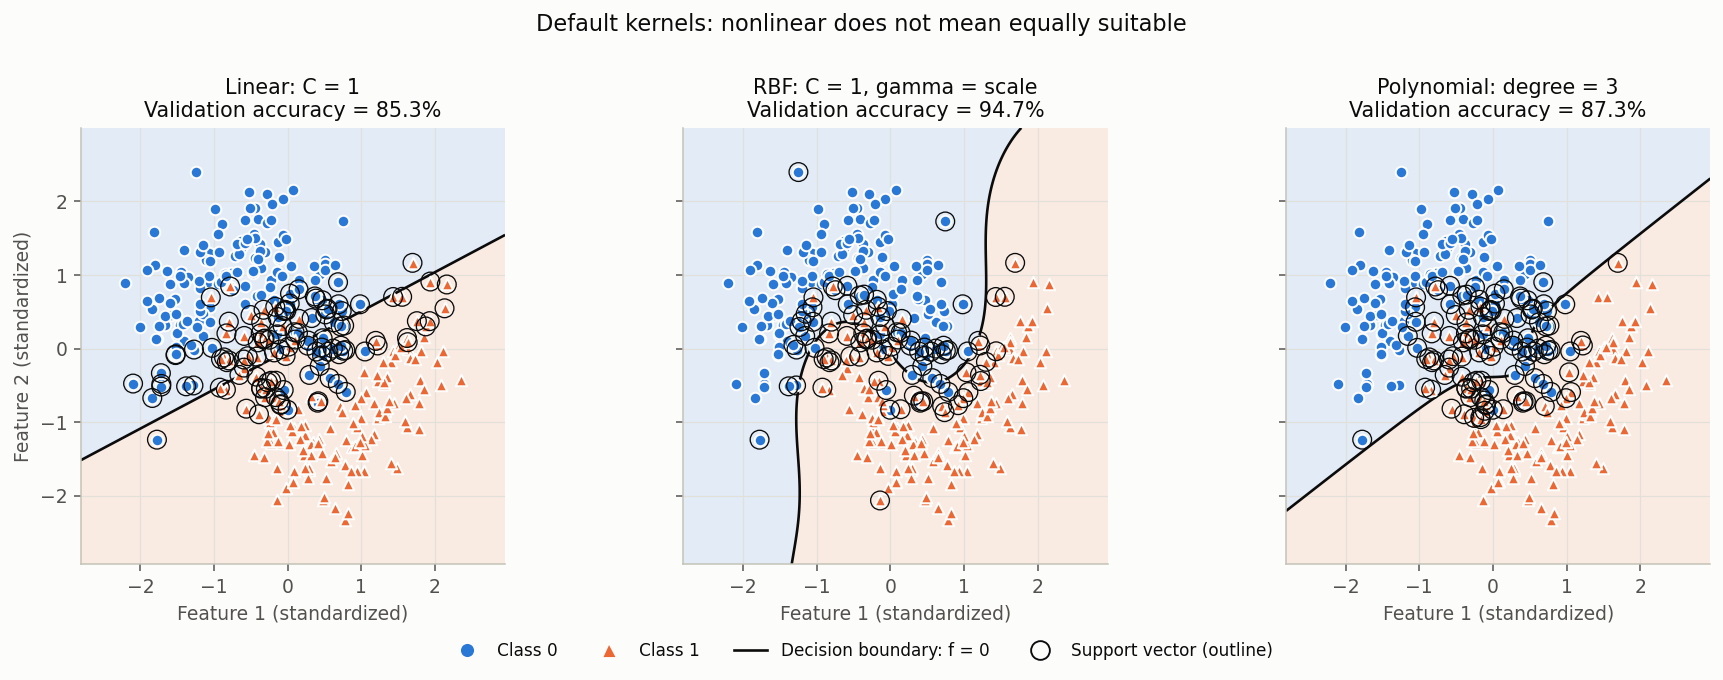

In [12]:
# Figure 3: all three default kernels on the same standardized mesh
fig, axes = plt.subplots(1, 3, figsize=(14, 5.0), sharex=True, sharey=True)
for ax, model, result, name in [
    (axes[0], linear_model, linear_result, 'Linear: C = 1'),
    (axes[1], rbf_model, rbf_result, 'RBF: C = 1, gamma = scale'),
    (axes[2], poly_model, poly_result, 'Polynomial: degree = 3'),
]:
    plot_decision_regions(ax, model,
                          f"{name}\nValidation accuracy = {result['Validation accuracy']:.1%}")
axes[0].set_ylabel('Feature 2 (standardized)')
fig.suptitle('Default kernels: nonlinear does not mean equally suitable', fontsize=12)
fig.legend(handles=boundary_legend(), loc='lower center', ncol=4, bbox_to_anchor=(0.5, 0.0), fontsize=9)
fig.tight_layout(rect=(0, 0.1, 1, 0.92))
plt.show()

## Task 4 — Hyperparameter tuning with GridSearchCV (30 marks)

The required grid contains **4 C values × 4 gamma values × 1 kernel = 16 candidates**. Five-fold CV fits each candidate five times, giving **80 CV fits**, followed by one refit of the selected candidate on all 350 training rows.

- `scoring='accuracy'`: choose by mean CV accuracy, not the 30% hold-out score.
- `cv=5`: for this classifier, scikit-learn uses stratified five-fold splits, with no fold shuffling by default.
- `refit=True`: retrain the best candidate on the full standardized training set.
- `verbose=2`: show progress, matching the handout.

The following is the **literal handout implementation** on `X_train_scaled`. A separate pipeline audit immediately afterward demonstrates fold-local preprocessing, which is preferable for strict CV hygiene. We keep the requested grid-search object and final model unmodified so the assignment results remain directly reproducible.

In [13]:
# Exact search space and GridSearchCV settings requested by the handout
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.1, 1, 10, 100],
    'kernel': ['rbf'],
}

grid = GridSearchCV(
    SVC(random_state=RANDOM_STATE),
    param_grid, refit=True, verbose=2, cv=5, scoring='accuracy',
    n_jobs=1, return_train_score=True,
)
started = time.perf_counter()
grid.fit(X_train_scaled, y_train)
grid_fit_seconds = time.perf_counter() - started

best_cv_std = float(grid.cv_results_['std_test_score'][grid.best_index_])
print('\nBest parameters:', grid.best_params_)
print(f'Best cross-validated accuracy: {grid.best_score_:.4f} ({grid.best_score_:.2%})')
print(f'Fold-score standard deviation for that candidate: {best_cv_std:.4f}')
print('Number of candidates:', len(grid.cv_results_['params']), '| CV folds:', grid.n_splits_)
print(f'Search and refit duration: {grid_fit_seconds:.2f} seconds')
print('Best estimator:', grid.best_estimator_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END ........................C=0.1, gamma=10, kernel=rbf; total time=   0.0s
[CV] END ........................C=0.1, gamma=10

In [14]:
# Inspect every candidate: these validation scores are INTERNAL CV folds, not X_val.
cv_table = pd.DataFrame({
    'C': [float(params['C']) for params in grid.cv_results_['params']],
    'gamma': [float(params['gamma']) for params in grid.cv_results_['params']],
    'Mean training-fold accuracy': grid.cv_results_['mean_train_score'],
    'Mean CV accuracy': grid.cv_results_['mean_test_score'],
    'CV std': grid.cv_results_['std_test_score'],
    'Rank': grid.cv_results_['rank_test_score'],
}).sort_values(['Rank', 'C', 'gamma']).reset_index(drop=True)
cv_table['Train minus CV'] = cv_table['Mean training-fold accuracy'] - cv_table['Mean CV accuracy']
display(cv_table.round(4))

print('A large training-minus-CV gap can indicate overfitting.')
print('The fold standard deviation describes score variation; it is not a confidence interval.')
print('A best grid point is best among these 16 candidates, not a proven global optimum.')

,C,gamma,Mean training-fold accuracy,Mean CV accuracy,CV std,Rank,Train minus CV
0,1.0,1.0,0.9564,0.9514,0.0265,1,0.0050
1,1.0,10.0,0.9643,0.9457,0.0246,2,0.0186
2,100.0,0.1,0.9436,0.9429,0.0239,3,0.0007
3,0.1,10.0,0.9586,0.9371,0.0214,4,0.0214
4,10.0,1.0,0.9621,0.9371,0.0194,4,0.0250
5,100.0,1.0,0.9614,0.9314,0.0277,6,0.0300
6,0.1,1.0,0.9300,0.9286,0.0202,7,0.0014
7,10.0,10.0,0.9750,0.9257,0.0210,8,0.0493
8,100.0,10.0,0.9921,0.9143,0.0128,9,0.0779
9,10.0,0.1,0.9050,0.8943,0.0265,10,0.0107


A large training-minus-CV gap can indicate overfitting.
The fold standard deviation describes score variation; it is not a confidence interval.
A best grid point is best among these 16 candidates, not a proven global optimum.


### Visualizing the C/gamma search

Each heatmap cell is the mean accuracy over five training-set CV folds. Rows and columns are logarithmically spaced candidate values, displayed as **discrete search choices**, not a continuous linear scale. The outlined cell marks the candidate selected by `GridSearchCV`. The complete numerical table above is the table-view equivalent of this figure.

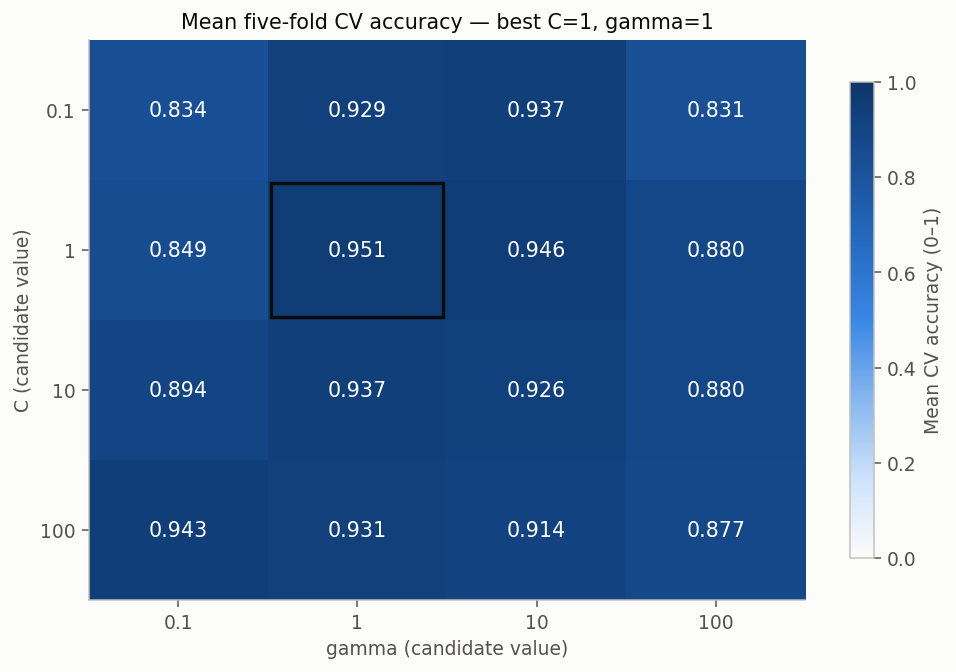

In [15]:
# Figure 4: accuracy for every C/gamma combination
cv_heatmap = cv_table.pivot(index='C', columns='gamma', values='Mean CV accuracy').reindex(
    index=param_grid['C'], columns=param_grid['gamma']
)
fig, ax = plt.subplots(figsize=(7.5, 5.1))
normalizer = Normalize(vmin=0, vmax=1)
image = ax.imshow(cv_heatmap.to_numpy(), cmap=SEQUENTIAL_CMAP, norm=normalizer, aspect='auto')
for row in range(len(cv_heatmap.index)):
    for col in range(len(cv_heatmap.columns)):
        score = float(cv_heatmap.iloc[row, col])
        ax.text(col, row, f'{score:.3f}', ha='center', va='center', fontsize=11,
                color=readable_cell_ink(SEQUENTIAL_CMAP(normalizer(score))))
best_row = param_grid['C'].index(grid.best_params_['C'])
best_col = param_grid['gamma'].index(grid.best_params_['gamma'])
ax.add_patch(Rectangle((best_col - 0.48, best_row - 0.48), 0.96, 0.96,
                       fill=False, edgecolor=STYLE['ink'], linewidth=1.8))
ax.set_xticks(range(4), [f'{value:g}' for value in param_grid['gamma']])
ax.set_yticks(range(4), [f'{value:g}' for value in param_grid['C']])
ax.set(xlabel='gamma (candidate value)', ylabel='C (candidate value)',
       title=f"Mean five-fold CV accuracy — best C={grid.best_params_['C']:g}, gamma={grid.best_params_['gamma']:g}")
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax, shrink=0.85)
colorbar.set_label('Mean CV accuracy (0–1)')
fig.tight_layout()
plt.show()

### Additional rigor: fold-local scaling audit

There is an important distinction between **hold-out leakage** and **CV-fold preprocessing leakage**:

1. The scaler above never sees the 150 hold-out rows, so there is no hold-out preprocessing leakage.
2. Following the handout literally means the scaler sees all 350 training rows **before** their CV subdivision. Therefore a CV validation fold contributes to the scaling statistics of that search. This can slightly influence its CV score, even though labels are not used by the scaler.

A `Pipeline(StandardScaler, SVC)` solves the second issue by fitting a new scaler on each fold's training portion. The audit below searches the **same parameter values**, using raw training features because scaling now happens inside the pipeline. Prefixes such as `svc__C` address the SVC step. This audit is not a new validation-driven search and does not change the required `grid` model.

In a production workflow, the pipeline form would normally be the primary model-selection implementation. Its refit also learns preprocessing only from the full training set.

In [16]:
# Optional correctness audit: StandardScaler is fitted separately inside each CV fold.
pipeline_grid = GridSearchCV(
    Pipeline([('scaler', StandardScaler()),
              ('svc', SVC(random_state=RANDOM_STATE))]),
    {f'svc__{key}': values for key, values in param_grid.items()},
    scoring='accuracy', cv=5, refit=True, verbose=0, n_jobs=1,
)
pipeline_grid.fit(X_train, y_train)  # RAW input: the pipeline owns the scaling.

print('Fold-local pipeline best parameters:', pipeline_grid.best_params_)
print(f'Fold-local pipeline best CV accuracy: {pipeline_grid.best_score_:.4f}')
print(f'Handout pre-scaled best CV accuracy: {grid.best_score_:.4f}')
print('The difference is an audit of preprocessing, not a hold-out model-selection criterion.')

audit_scaler = pipeline_grid.best_estimator_.named_steps['scaler']
assert np.allclose(audit_scaler.mean_, X_train.mean(axis=0))
assert int(audit_scaler.n_samples_seen_) == len(X_train)
assert len(pipeline_grid.cv_results_['params']) == 16

Fold-local pipeline best parameters: {'svc__C': 1, 'svc__gamma': 1, 'svc__kernel': 'rbf'}
Fold-local pipeline best CV accuracy: 0.9486
Handout pre-scaled best CV accuracy: 0.9514
The difference is an audit of preprocessing, not a hold-out model-selection criterion.


## Task 5 — Final evaluation and visualization (20 marks)

The required final model is `grid`, whose best candidate was selected from training-set CV and refitted on all 350 standardized training observations. Predict the 150 validation observations using `grid.predict(X_val_scaled)`.

These are **hold-out validation results**, not training accuracy or the best CV score. Baseline comparisons were requested on this same hold-out set, so it should not be described as a completely untouched, independent test set. We do not adjust the parameter grid or select another model after seeing these results.

In [17]:
# Final predictions from the requested best-model object
final_predictions = grid.predict(X_val_scaled)
final_accuracy = accuracy_score(y_val, final_predictions)
final_report_text = classification_report(
    y_val, final_predictions, labels=[0, 1],
    target_names=['Class 0', 'Class 1'], digits=4, zero_division=0,
)
final_report_dict = classification_report(
    y_val, final_predictions, labels=[0, 1],
    target_names=['Class 0', 'Class 1'], output_dict=True, zero_division=0,
)

print('FINAL TUNED RBF — HOLD-OUT VALIDATION PERFORMANCE')
print('Selected parameters:', grid.best_params_)
print(f'Validation accuracy: {final_accuracy:.4f} ({final_accuracy:.2%})')
print(final_report_text)

report_table = pd.DataFrame({
    key: final_report_dict[key] for key in ['Class 0', 'Class 1', 'macro avg', 'weighted avg']
}).T
report_table['support'] = report_table['support'].astype(int)
display(report_table.round(4))

FINAL TUNED RBF — HOLD-OUT VALIDATION PERFORMANCE
Selected parameters: {'C': 1, 'gamma': 1, 'kernel': 'rbf'}
Validation accuracy: 0.9667 (96.67%)
              precision    recall  f1-score   support

     Class 0     0.9375    1.0000    0.9677        75
     Class 1     1.0000    0.9333    0.9655        75

    accuracy                         0.9667       150
   macro avg     0.9688    0.9667    0.9666       150
weighted avg     0.9688    0.9667    0.9666       150



,precision,recall,f1-score,support
Class 0,0.9375,1.0000,0.9677,75
Class 1,1.0000,0.9333,0.9655,75
macro avg,0.9688,0.9667,0.9666,150
weighted avg,0.9688,0.9667,0.9666,150


In [18]:
# FINAL FOUR-MODEL COMPARISON required by the submission guidelines
final_precision, final_recall, final_f1, _ = precision_recall_fscore_support(
    y_val, final_predictions, average='macro', zero_division=0
)
tuned_result = {
    'Model': 'Tuned RBF (GridSearchCV)',
    'Training accuracy': grid.score(X_train_scaled, y_train),
    'Validation accuracy': final_accuracy,
    'Precision (macro)': final_precision, 'Recall (macro)': final_recall,
    'F1 (macro)': final_f1,
    'Support vectors': int(grid.best_estimator_.n_support_.sum()),
}
comparison_final = pd.DataFrame([linear_result, rbf_result, poly_result, tuned_result])
print('FINAL FOUR-MODEL COMPARISON — SAME 150-ROW VALIDATION SET')
print(comparison_final[['Model', 'Validation accuracy']].to_string(index=False,
      float_format=lambda value: f'{value:.4f}'))
display(comparison_final.round(4))

validation_majority_baseline = max(int((y_val == 0).sum()), int((y_val == 1).sum())) / len(y_val)
print(f'Validation majority-class reference accuracy: {validation_majority_baseline:.2%}')
print('This reference describes class balance; it is not a fifth fitted SVM model.')

FINAL FOUR-MODEL COMPARISON — SAME 150-ROW VALIDATION SET
                   Model  Validation accuracy
            Linear (C=1)               0.8533
           RBF (default)               0.9467
   Polynomial (degree=3)               0.8733
Tuned RBF (GridSearchCV)               0.9667


,Model,Training accuracy,Validation accuracy,Precision (macro),Recall (macro),F1 (macro),Support vectors
0,Linear (C=1),0.8457,0.8533,0.8536,0.8533,0.8533,117
1,RBF (default),0.9457,0.9467,0.9495,0.9467,0.9466,95
2,Polynomial (degree=3),0.8543,0.8733,0.8788,0.8733,0.8729,118
3,Tuned RBF (GridSearchCV),0.9571,0.9667,0.9688,0.9667,0.9666,82


Validation majority-class reference accuracy: 50.00%
This reference describes class balance; it is not a fifth fitted SVM model.


In [19]:
# Report the preprocessing audit separately; do not replace any of the four requested models.
# A Pipeline expects RAW validation coordinates, and applies its own fitted scaler.
audit_predictions = pipeline_grid.predict(X_val)
audit_accuracy = accuracy_score(y_val, audit_predictions)
audit_comparison = pd.DataFrame([
    {'Search': 'Handout: pre-scaled CV', 'Best CV accuracy': grid.best_score_,
     'Validation accuracy': final_accuracy, 'Best C': grid.best_params_['C'],
     'Best gamma': grid.best_params_['gamma']},
    {'Search': 'Audit: fold-local scaling', 'Best CV accuracy': pipeline_grid.best_score_,
     'Validation accuracy': audit_accuracy, 'Best C': pipeline_grid.best_params_['svc__C'],
     'Best gamma': pipeline_grid.best_params_['svc__gamma']},
])
display(audit_comparison.round(4))
print('Audit and handout predictions agree on',
      int((audit_predictions == final_predictions).sum()), 'of', len(y_val), 'validation rows.')

,Search,Best CV accuracy,Validation accuracy,Best C,Best gamma
0,Handout: pre-scaled CV,0.9514,0.9667,1,1
1,Audit: fold-local scaling,0.9486,0.9667,1,1


Audit and handout predictions agree on 150 of 150 validation rows.


### Confusion matrix

Rows represent **true classes** and columns represent **predicted classes**. With class 1 treated as positive, the entries are `[[TN, FP], [FN, TP]]`. A false positive is a class-0 observation predicted as class 1; a false negative is a class-1 observation predicted as class 0. The per-class report above complements accuracy by showing which class contributes errors.

,Predicted class 0,Predicted class 1
True class 0,75,0
True class 1,5,70


TN=75, FP=0, FN=5, TP=70; total=150; errors=5


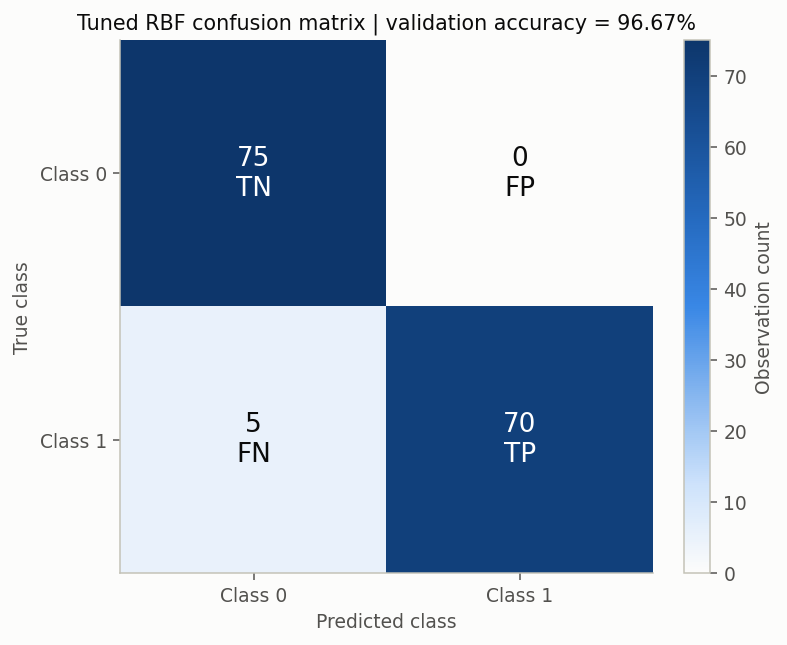

In [20]:
# Figure 5: final confusion matrix, with exact counts and an accompanying table
cm = confusion_matrix(y_val, final_predictions, labels=[0, 1])
tn, fp, fn, tp = map(int, cm.ravel())
confusion_table = pd.DataFrame(cm, index=['True class 0', 'True class 1'],
                             columns=['Predicted class 0', 'Predicted class 1'])
display(confusion_table)
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}; total={cm.sum()}; errors={fp + fn}')

fig, ax = plt.subplots(figsize=(6.4, 4.9))
cm_normalizer = Normalize(vmin=0, vmax=max(1, int(cm.max())))
image = ax.imshow(cm, cmap=SEQUENTIAL_CMAP, norm=cm_normalizer)
cell_names = [['TN', 'FP'], ['FN', 'TP']]
for row in range(2):
    for col in range(2):
        count = int(cm[row, col])
        ax.text(col, row, f'{count}\n{cell_names[row][col]}', ha='center', va='center',
                fontsize=14, color=readable_cell_ink(SEQUENTIAL_CMAP(cm_normalizer(count))))
ax.set_xticks([0, 1], ['Class 0', 'Class 1'])
ax.set_yticks([0, 1], ['Class 0', 'Class 1'])
ax.set(xlabel='Predicted class', ylabel='True class',
       title=f'Tuned RBF confusion matrix | validation accuracy = {final_accuracy:.2%}')
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
colorbar.set_label('Observation count')
fig.tight_layout()
plt.show()

### Required 1×3 decision-boundary comparison

The panels below show **linear**, **default RBF**, and **GridSearchCV best RBF**, in that order. Each uses `np.meshgrid`, predictions on every mesh point, and `plt.contourf` decision regions, with the standardized **training points** overlaid exactly as requested. The solid contour is $f(x)=0$; rings highlight support vectors.

The accuracy in each title comes from the **validation** set, not from the points displayed. This distinction prevents a training-point plot from being mistaken for a visual test-set evaluation. A curved boundary that follows the moons is more appropriate than a straight separator, but unnecessarily intricate regions can reflect noise rather than generalizable structure.

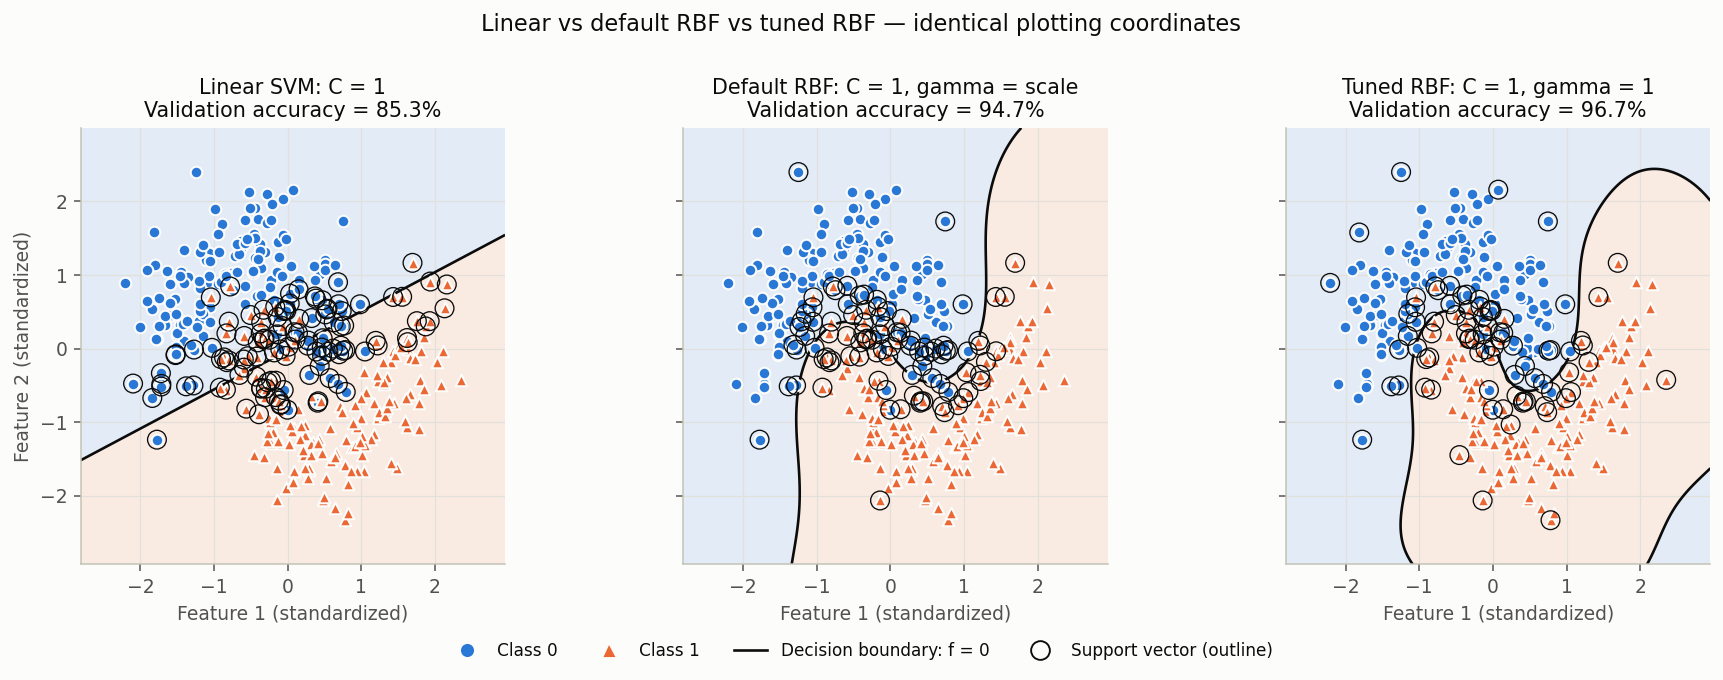

In [21]:
# Figure 6: THE REQUIRED 1 x 3 SUBPLOT from Task 5
boundary_figure, axes = plt.subplots(1, 3, figsize=(14, 5.0), sharex=True, sharey=True)
final_panels = [
    (linear_model, 'Linear SVM: C = 1', linear_result['Validation accuracy']),
    (rbf_model, 'Default RBF: C = 1, gamma = scale', rbf_result['Validation accuracy']),
    (grid, f"Tuned RBF: C = {grid.best_params_['C']:g}, gamma = {grid.best_params_['gamma']:g}", final_accuracy),
]
for ax, (model, name, score) in zip(axes, final_panels):
    plot_decision_regions(ax, model, f'{name}\nValidation accuracy = {score:.1%}')
axes[0].set_ylabel('Feature 2 (standardized)')
boundary_figure.suptitle('Linear vs default RBF vs tuned RBF — identical plotting coordinates', fontsize=12)
boundary_figure.legend(handles=boundary_legend(), loc='lower center', ncol=4,
                       bbox_to_anchor=(0.5, 0.0), fontsize=9)
boundary_figure.tight_layout(rect=(0, 0.1, 1, 0.92))
plt.show()

## Additional analysis — What if gamma is too high or C is too low?

The handout explicitly asks about `gamma=1000` and `C=0.01`. These controlled demonstrations change **one setting at a time** relative to the default RBF model:

- **Very high gamma:** C = 1, gamma = 1000. The characteristic RBF influence length is about $1/\sqrt{\gamma}$, so effects become extremely local. Tiny islands around training samples can give high training accuracy but poor CV accuracy. Away from those islands, predictions can largely follow the intercept.
- **Very low C:** C = 0.01, gamma = 'scale'. Strong regularization tolerates many margin violations and can underfit, producing a much simpler or weak decision surface.

These models are **not added to the search space and are not chosen using the hold-out set**. Their generalization behavior is assessed with training-only, fold-local pipeline CV. The same standardized-coordinate mesh is used for their illustrations; very small islands can be finer than the plotting mesh, so the figure is an approximation, not an exact geometric reconstruction.

In [22]:
# Controlled sensitivity demonstrations, evaluated without further hold-out tuning
high_gamma_model = SVC(kernel='rbf', C=1.0, gamma=1000, random_state=RANDOM_STATE)
low_c_model = SVC(kernel='rbf', C=0.01, gamma='scale', random_state=RANDOM_STATE)
high_gamma_model.fit(X_train_scaled, y_train)
low_c_model.fit(X_train_scaled, y_train)

sensitivity_specs = [
    ('Default RBF', rbf_model),
    ('Very high gamma', high_gamma_model),
    ('Very low C', low_c_model),
]
sensitivity_rows = []
for name, model in sensitivity_specs:
    params = {key: model.get_params()[key] for key in ['kernel', 'C', 'gamma', 'random_state']}
    fold_local_model = Pipeline([('scaler', StandardScaler()), ('svc', SVC(**params))])
    fold_scores = cross_val_score(fold_local_model, X_train, y_train, cv=5, scoring='accuracy')
    sensitivity_rows.append({
        'Setting': name, 'C': params['C'], 'gamma': params['gamma'],
        'Training accuracy': model.score(X_train_scaled, y_train),
        'Mean fold-local CV accuracy': fold_scores.mean(), 'CV std': fold_scores.std(),
        'Support vectors': int(model.n_support_.sum()),
    })
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.round(4))
print('No validation-set scores were used for these additional sensitivity experiments.')

,Setting,C,gamma,Training accuracy,Mean fold-local CV accuracy,CV std,Support vectors
0,Default RBF,1.00,scale,0.9457,0.9400,0.0210,95
1,Very high gamma,1.00,1000,1.0000,0.6743,0.0805,350
2,Very low C,0.01,scale,0.8543,0.8514,0.0171,350


No validation-set scores were used for these additional sensitivity experiments.


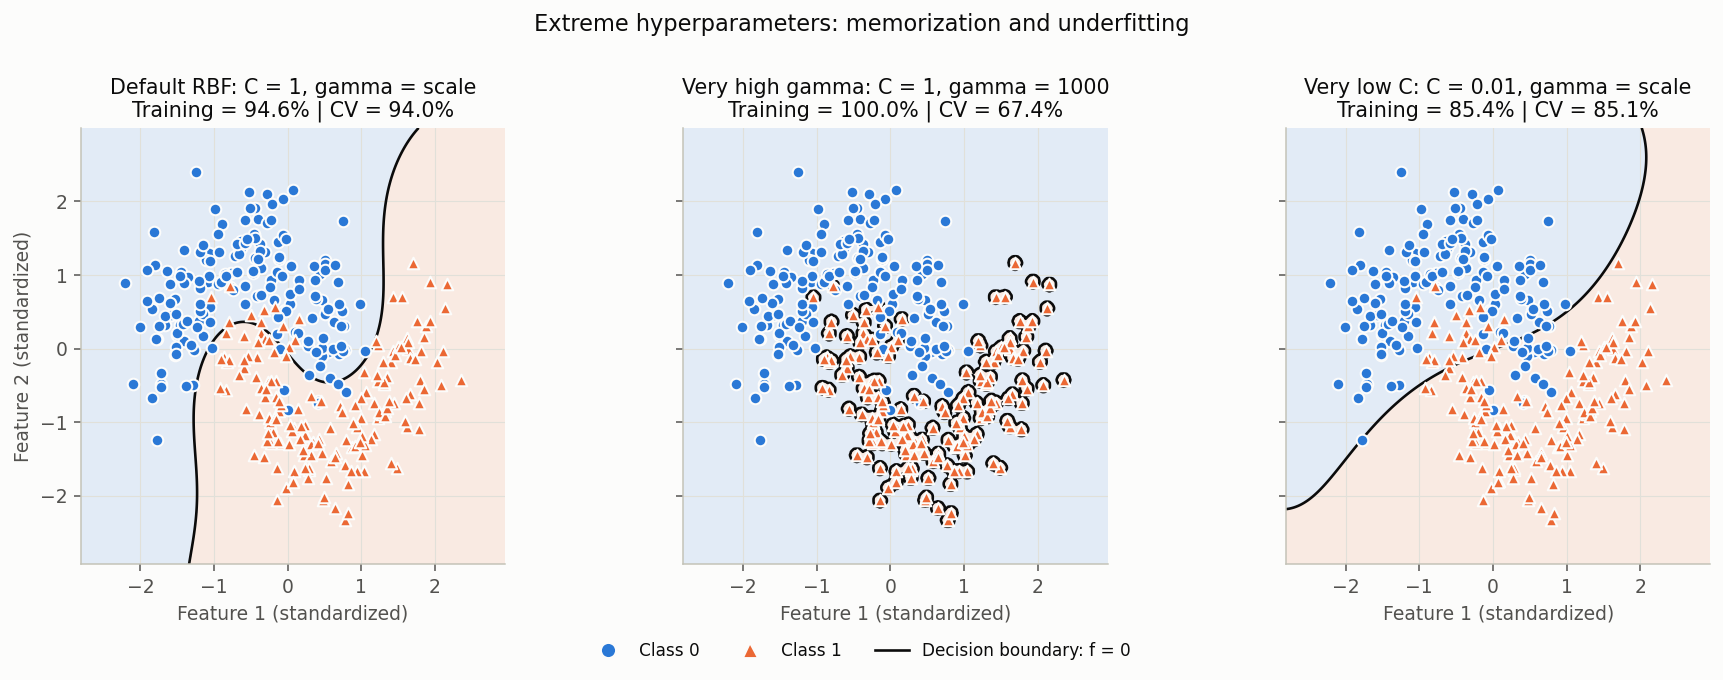

In [23]:
# Figure 7: what extreme gamma and C do to the decision regions
fig, axes = plt.subplots(1, 3, figsize=(14, 5.0), sharex=True, sharey=True)
for ax, (name, model), row in zip(axes, sensitivity_specs, sensitivity_rows):
    params = model.get_params()
    title = (f"{name}: C = {params['C']:g}, gamma = {params['gamma']}\n"
             f"Training = {row['Training accuracy']:.1%} | CV = {row['Mean fold-local CV accuracy']:.1%}")
    # Hundreds of outline rings would obscure the high-gamma example.
    plot_decision_regions(ax, model, title, show_support=False)
axes[0].set_ylabel('Feature 2 (standardized)')
fig.suptitle('Extreme hyperparameters: memorization and underfitting', fontsize=12)
fig.legend(handles=boundary_legend(show_support=False), loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, 0.0), fontsize=9)
fig.tight_layout(rect=(0, 0.1, 1, 0.92))
plt.show()

## Report-ready results and conclusion

The next cell builds its table and answers directly from the fitted models, so the prose remains consistent if the notebook is rerun. It also reports a Wilson interval for the final validation accuracy. That interval describes finite-sample binomial uncertainty for this 150-row evaluation; it does **not** include uncertainty from model selection, repeated comparison, or changes to the data distribution.

### Interpretation cautions

- The best CV score, training accuracy, and hold-out validation accuracy answer different questions.
- The best hyperparameters are optimal only within the required 16-point grid. A larger search is not automatically better and must not be guided by this hold-out set.
- One random split of 500 synthetic observations is an educational demonstration, not proof of performance on all nonlinear data.
- We deliberately follow the prescribed pre-scaled grid for the main results and disclose its CV preprocessing limitation. The pipeline audit provides the stricter alternative.
- Because the same validation set is displayed for several requested models, a future model-selection project should reserve another genuinely untouched test set or use nested CV.

In [24]:
# A computed, report-ready conclusion — no invented or hard-coded result values
n_validation = len(y_val)
correct_predictions = int((y_val == final_predictions).sum())
z = 1.959963984540054
denominator = 1.0 + z ** 2 / n_validation
wilson_center = (final_accuracy + z ** 2 / (2.0 * n_validation)) / denominator
wilson_half = z * np.sqrt(
    final_accuracy * (1.0 - final_accuracy) / n_validation
    + z ** 2 / (4.0 * n_validation ** 2)
) / denominator
wilson_low, wilson_high = wilson_center - wilson_half, wilson_center + wilson_half

comparison_markdown = '\n'.join([
    '| Model | Validation accuracy | Macro F1 | Support vectors |',
    '|---|---:|---:|---:|',
] + [
    f"| {row['Model']} | {row['Validation accuracy']:.2%} | {row['F1 (macro)']:.4f} | {row['Support vectors']} |"
    for row in comparison_final.to_dict('records')
])
high_gamma_row = sensitivity_rows[1]
low_c_row = sensitivity_rows[2]
rbf_change = final_accuracy - rbf_result['Validation accuracy']

conclusion = f'''### Four-model comparison

{comparison_markdown}

### Answers to the handout's conclusion questions

**1. Why did the linear SVM fail, and why did RBF succeed?**  
The linear model achieved **{linear_result['Validation accuracy']:.2%}**, but its straight boundary cannot follow two interlocking curved arcs. The default RBF achieved **{rbf_result['Validation accuracy']:.2%}**: distance-based local similarities allow a nonlinear contour around the moons. Noise and class overlap still create difficult observations. The default polynomial model achieved **{poly_result['Validation accuracy']:.2%}**; a nonlinear kernel is not automatically a good fit at its default settings. The best default kernel(s) in this run were **{', '.join(best_default_names)}**.

**2. What did GridSearchCV tell us?**  
Among the required 16 RBF candidates, it selected **C = {grid.best_params_['C']:g}** and **gamma = {grid.best_params_['gamma']:g}**, with mean five-fold training-set CV accuracy **{grid.best_score_:.2%}** (fold standard deviation **{best_cv_std:.4f}**). After refitting, the selected model correctly classified **{correct_predictions}/{n_validation}** hold-out observations: **{final_accuracy:.2%}** accuracy, a change of **{rbf_change * 100:+.2f} percentage points** from the default RBF. A grid search does not guarantee an improvement on every hold-out sample.

**3. What happens when gamma is too high, for example 1000?**  
The RBF influence becomes extremely narrow, so the model can create small islands around individual training points rather than a stable curved separator. Here, gamma = 1000 with C = 1 gave **{high_gamma_row['Training accuracy']:.2%}** training accuracy but **{high_gamma_row['Mean fold-local CV accuracy']:.2%}** fold-local CV accuracy. This contrast illustrates why a highly detailed boundary and a high training score can be misleading.

**4. What happens when C is too low, for example 0.01?**  
Margin violations become cheap and regularization becomes strong. The RBF example with C = 0.01 and gamma = 'scale' gave **{low_c_row['Training accuracy']:.2%}** training accuracy and **{low_c_row['Mean fold-local CV accuracy']:.2%}** fold-local CV accuracy. Its simpler decision surface can underfit; for a linear SVM the boundary would still be straight, with more tolerated violations and generally a wider margin.

### Final performance

- **Accuracy:** {final_accuracy:.2%}; approximate 95% Wilson interval **[{wilson_low:.2%}, {wilson_high:.2%}]** for sampling uncertainty only.
- **Macro precision / recall / F1:** {final_precision:.4f} / {final_recall:.4f} / {final_f1:.4f}.
- **Confusion counts (class 1 positive):** TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}.
- **Fold-local audit:** best CV accuracy {pipeline_grid.best_score_:.2%}, hold-out accuracy {audit_accuracy:.2%}. This is reported separately and does not replace the four requested models.

**Overall conclusion:** scaling, an appropriate nonlinear kernel, and training-only hyperparameter selection matter more than simply maximizing model complexity. The required plots explain the numerical comparison, while the CV audit and explicit split terminology keep the performance claims honest.
'''
display(Markdown(conclusion))

### Four-model comparison

| Model | Validation accuracy | Macro F1 | Support vectors |
|---|---:|---:|---:|
| Linear (C=1) | 85.33% | 0.8533 | 117 |
| RBF (default) | 94.67% | 0.9466 | 95 |
| Polynomial (degree=3) | 87.33% | 0.8729 | 118 |
| Tuned RBF (GridSearchCV) | 96.67% | 0.9666 | 82 |

### Answers to the handout's conclusion questions

**1. Why did the linear SVM fail, and why did RBF succeed?**  
The linear model achieved **85.33%**, but its straight boundary cannot follow two interlocking curved arcs. The default RBF achieved **94.67%**: distance-based local similarities allow a nonlinear contour around the moons. Noise and class overlap still create difficult observations. The default polynomial model achieved **87.33%**; a nonlinear kernel is not automatically a good fit at its default settings. The best default kernel(s) in this run were **RBF (default)**.

**2. What did GridSearchCV tell us?**  
Among the required 16 RBF candidates, it selected **C = 1** and **gamma = 1**, with mean five-fold training-set CV accuracy **95.14%** (fold standard deviation **0.0265**). After refitting, the selected model correctly classified **145/150** hold-out observations: **96.67%** accuracy, a change of **+2.00 percentage points** from the default RBF. A grid search does not guarantee an improvement on every hold-out sample.

**3. What happens when gamma is too high, for example 1000?**  
The RBF influence becomes extremely narrow, so the model can create small islands around individual training points rather than a stable curved separator. Here, gamma = 1000 with C = 1 gave **100.00%** training accuracy but **67.43%** fold-local CV accuracy. This contrast illustrates why a highly detailed boundary and a high training score can be misleading.

**4. What happens when C is too low, for example 0.01?**  
Margin violations become cheap and regularization becomes strong. The RBF example with C = 0.01 and gamma = 'scale' gave **85.43%** training accuracy and **85.14%** fold-local CV accuracy. Its simpler decision surface can underfit; for a linear SVM the boundary would still be straight, with more tolerated violations and generally a wider margin.

### Final performance

- **Accuracy:** 96.67%; approximate 95% Wilson interval **[92.43%, 98.57%]** for sampling uncertainty only.
- **Macro precision / recall / F1:** 0.9688 / 0.9667 / 0.9666.
- **Confusion counts (class 1 positive):** TN = 75, FP = 0, FN = 5, TP = 70.
- **Fold-local audit:** best CV accuracy 94.86%, hold-out accuracy 96.67%. This is reported separately and does not replace the four requested models.

**Overall conclusion:** scaling, an appropriate nonlinear kernel, and training-only hyperparameter selection matter more than simply maximizing model complexity. The required plots explain the numerical comparison, while the CV audit and explicit split terminology keep the performance claims honest.


## Reproducibility and implementation checks

The assertions below verify the assignment's sample counts, split, fitted scaler, search size, final predictions, model comparison and required figure layout. They test structural correctness without hard-coding a library-version-dependent expected accuracy. A complete run should print PASS for every check.

In [25]:
# FINAL VALIDATION SUMMARY
checks = {
    'Exact 500-sample, two-feature dataset': X.shape == (500, 2) and y.shape == (500,),
    'Exact 70/30 split': len(y_train) == 350 and len(y_val) == 150,
    'No shared training/validation observations': train_rows.isdisjoint(validation_rows),
    'Scaler fitted on training only': np.allclose(scaler.mean_, X_train.mean(axis=0))
                                    and int(scaler.n_samples_seen_) == 350,
    'Training means 0 and stds 1 after scaling': np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-12)
                                              and np.allclose(X_train_scaled.std(axis=0), 1, atol=1e-12),
    'Required linear/RBF/polynomial kernels': [model.kernel for model in [linear_model, rbf_model, poly_model]]
                                             == ['linear', 'rbf', 'poly'],
    'Required degree-3 polynomial': poly_model.degree == 3,
    '16 candidates and five CV folds': len(grid.cv_results_['params']) == 16 and grid.n_splits_ == 5,
    'Refitted best estimator is RBF': grid.refit and grid.best_estimator_.kernel == 'rbf',
    'Final predictions match grid.predict': np.array_equal(final_predictions, grid.predict(X_val_scaled)),
    'Exactly four requested comparison models': len(comparison_final) == 4,
    'Confusion matrix contains all 150 predictions': cm.shape == (2, 2) and int(cm.sum()) == 150,
    'Accuracy agrees with confusion-matrix trace': np.isclose(np.trace(cm) / cm.sum(), final_accuracy),
    'Required final plot contains three panels': len(boundary_figure.axes) == 3,
    'Fold-local audit refit uses training rows only': int(audit_scaler.n_samples_seen_) == 350
                                                   and np.allclose(audit_scaler.mean_, X_train.mean(axis=0)),
}
failed_checks = [name for name, passed in checks.items() if not passed]
assert not failed_checks, f'Failed checks: {failed_checks}'
for name in checks:
    print('PASS —', name)
print(f'\nAll {len(checks)} checks passed. Final validation accuracy: {final_accuracy:.2%}.')

PASS — Exact 500-sample, two-feature dataset
PASS — Exact 70/30 split
PASS — No shared training/validation observations
PASS — Scaler fitted on training only
PASS — Training means 0 and stds 1 after scaling
PASS — Required linear/RBF/polynomial kernels
PASS — Required degree-3 polynomial
PASS — 16 candidates and five CV folds
PASS — Refitted best estimator is RBF
PASS — Final predictions match grid.predict
PASS — Exactly four requested comparison models
PASS — Confusion matrix contains all 150 predictions
PASS — Accuracy agrees with confusion-matrix trace
PASS — Required final plot contains three panels
PASS — Fold-local audit refit uses training rows only

All 15 checks passed. Final validation accuracy: 96.67%.
